# Sentiment Analysis of LGBTQ+ Corporate Tweets Using VADER


## Overview

This notebook applies **VADER sentiment analysis** to the LGBTQ+ labeled subset of corporate tweets from the main dataset.



---
## Section 1 — Setup

### 1.1 — Install & Import Libraries

VADER is part of the `nltk` library. We install it here so this notebook is self-contained.

In [1]:
# ── Install NLTK (includes VADER) ────────────────────────────────────────────
!pip install nltk --quiet

In [2]:
# ── Core libraries ───────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# ── VADER ────────────────────────────────────────────────────────────────────
import nltk
nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# ── Plot styling (matches main notebook) ────────────────────────────────────
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.15)
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'figure.titlesize': 16,
    'figure.titleweight': 'bold',
})

# ── Colors (matches main notebook) ──────────────────────────────────────────
LGBTQ_COLOR     = '#8B5CF6'   # purple
NON_LGBTQ_COLOR = '#64748B'   # slate gray
ACCENT_COLOR    = '#F59E0B'   # amber
POS_COLOR       = '#22C55E'   # green  — positive sentiment
NEU_COLOR       = '#94A3B8'   # light gray — neutral sentiment
NEG_COLOR       = '#EF4444'   # red   — negative sentiment

print('✅ Libraries imported successfully.')

✅ Libraries imported successfully.


### 1.2 — Load Dataset



In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# ── Load full dataset ────────────────────────────────────────────────────────
FILE_PATH = '/content/drive/MyDrive/Colab Notebooks/Tweets.csv'

df = pd.read_csv(FILE_PATH, low_memory=False, on_bad_lines='skip')

# ── Parse dates and extract year / month ────────────────────────────────────
df['createdAt'] = pd.to_datetime(df['createdAt'], utc=True, errors='coerce')
df['year']      = df['createdAt'].dt.year
df['month']     = df['createdAt'].dt.month

print(f'✅ Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'   LGBTQ+ tweets : {(df["binary"] == 1).sum():,}  ({(df["binary"] == 1).mean()*100:.1f}% of total)')

✅ Dataset loaded: 1,585,500 rows × 19 columns
   LGBTQ+ tweets : 52,791  (3.3% of total)


### 1.3 — Filter to LGBTQ+ Tweets Only

VADER will only be run on LGBTQ+-labeled tweets. This keeps the analysis focused and is much faster than running it on all 1.5 million rows.

In [5]:
# ── Isolate LGBTQ+ tweets ────────────────────────────────────────────────────
df_lgbtq = df[df['binary'] == 1].copy().reset_index(drop=True)

print(f'✅ LGBTQ+ subset created: {len(df_lgbtq):,} tweets')
print(f'   Date range: {df_lgbtq["createdAt"].min().date()}  →  {df_lgbtq["createdAt"].max().date()}')
print(f'   Companies : {df_lgbtq["author_userName"].nunique():,}')

✅ LGBTQ+ subset created: 52,791 tweets
   Date range: 2018-01-01  →  2024-07-14
   Companies : 390


---
## Section 2 — Running VADER

VADER scores each tweet on positive, neutral, negative, and compound dimensions.

In [6]:
# ── Initialize VADER ─────────────────────────────────────────────────────────
sia = SentimentIntensityAnalyzer()

# ── Score every LGBTQ+ tweet ─────────────────────────────────────────────────
# polarity_scores() returns a dict with keys: neg, neu, pos, compound
print('Running VADER... (this may take 1–2 minutes)')
scores = df_lgbtq['text'].apply(lambda t: sia.polarity_scores(str(t)))

df_lgbtq['vader_pos']      = scores.apply(lambda s: s['pos'])
df_lgbtq['vader_neu']      = scores.apply(lambda s: s['neu'])
df_lgbtq['vader_neg']      = scores.apply(lambda s: s['neg'])
df_lgbtq['vader_compound'] = scores.apply(lambda s: s['compound'])

print('✅ VADER scores computed.')
print(f'   Columns added: vader_pos, vader_neu, vader_neg, vader_compound')

Running VADER... (this may take 1–2 minutes)
✅ VADER scores computed.
   Columns added: vader_pos, vader_neu, vader_neg, vader_compound


### 2.1 — Assign Sentiment Labels

The compound score summarizes the overall tone. We use the standard VADER thresholds to assign a label to each tweet:
- **Positive** — compound ≥ 0.05
- **Negative** — compound ≤ −0.05
- **Neutral** — everything in between

In [7]:
# ── Apply standard VADER thresholds ─────────────────────────────────────────
def label_sentiment(compound):
    if compound >= 0.05:
        return 'Positive'
    elif compound <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df_lgbtq['vader_label'] = df_lgbtq['vader_compound'].apply(label_sentiment)

# ── Summary counts ───────────────────────────────────────────────────────────
label_counts = df_lgbtq['vader_label'].value_counts()
label_pcts   = (label_counts / len(df_lgbtq) * 100).round(1)

summary = pd.DataFrame({'Count': label_counts, 'Percentage': label_pcts})
print('VADER SENTIMENT DISTRIBUTION — LGBTQ+ TWEETS')
print('═' * 45)
display(summary)

VADER SENTIMENT DISTRIBUTION — LGBTQ+ TWEETS
═════════════════════════════════════════════


,Count,Percentage
vader_label,,
Positive,42530,80.6
Neutral,7544,14.3
Negative,2717,5.1


---
## Section 3 — Overall Sentiment Distribution

### 3.1 — Sentiment Label Breakdown (Bar + Pie)

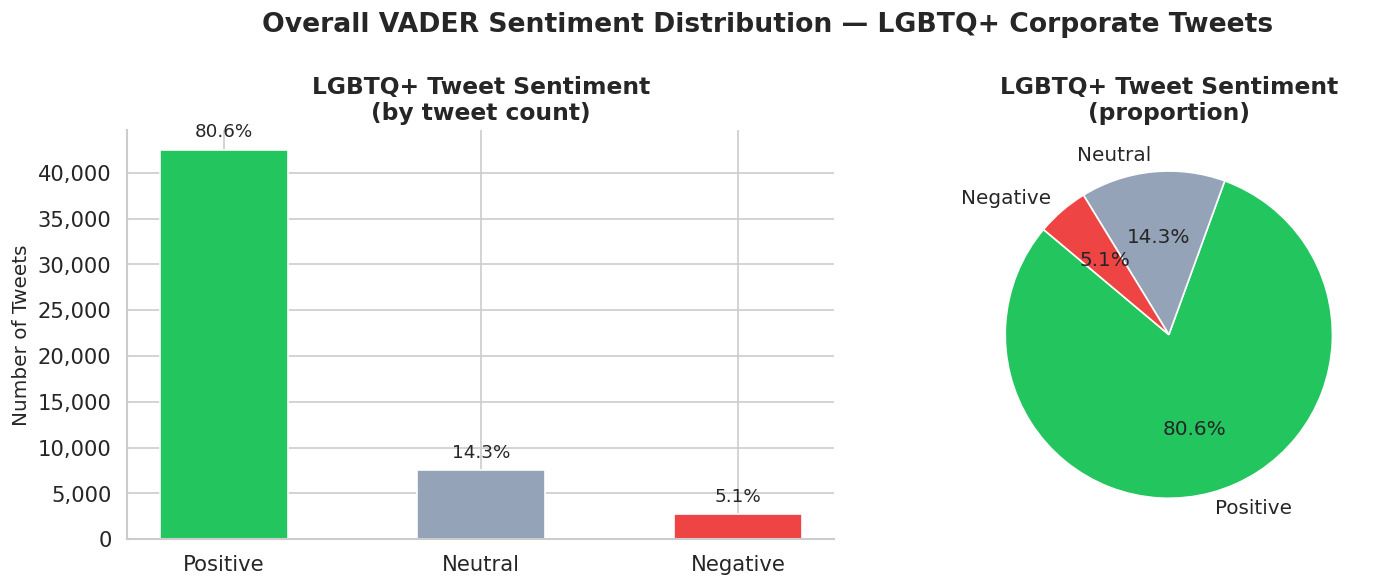

In [8]:
label_order  = ['Positive', 'Neutral', 'Negative']
label_colors = [POS_COLOR, NEU_COLOR, NEG_COLOR]

counts_ordered = [label_counts.get(l, 0) for l in label_order]
pcts_ordered   = [label_pcts.get(l, 0) for l in label_order]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Bar chart ────────────────────────────────────────────────────────────────
bars = axes[0].bar(label_order, counts_ordered, color=label_colors, edgecolor='white', width=0.5)
axes[0].bar_label(bars, labels=[f'{p:.1f}%' for p in pcts_ordered], padding=5, fontsize=11)
axes[0].set_title('LGBTQ+ Tweet Sentiment\n(by tweet count)')
axes[0].set_ylabel('Number of Tweets')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(ax=axes[0])

# ── Pie chart ────────────────────────────────────────────────────────────────
axes[1].pie(
    counts_ordered,
    labels=label_order,
    colors=label_colors,
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 12}
)
axes[1].set_title('LGBTQ+ Tweet Sentiment\n(proportion)')

fig.suptitle('Overall VADER Sentiment Distribution — LGBTQ+ Corporate Tweets')
plt.tight_layout()
plt.savefig('fig_vader_overall_dist.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.2 — Compound Score Distribution

The compound score gives a more granular view than just the three labels. A score of 0 is completely neutral; +1 is maximally positive.

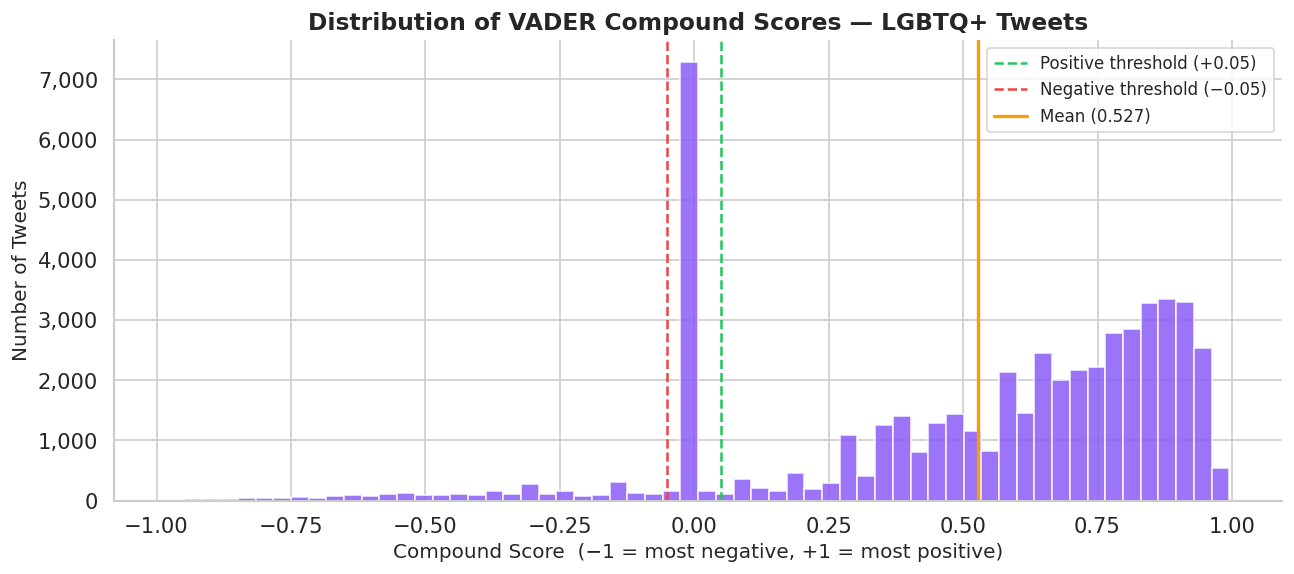

COMPOUND SCORE — SUMMARY STATISTICS
count    52791.000
mean         0.527
std          0.373
min         -0.981
25%          0.318
50%          0.637
75%          0.827
max          0.995


In [9]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    df_lgbtq['vader_compound'],
    bins=60,
    color=LGBTQ_COLOR,
    edgecolor='white',
    alpha=0.85
)

# ── Reference lines ──────────────────────────────────────────────────────────
ax.axvline(0.05,  color=POS_COLOR, linestyle='--', linewidth=1.5, label='Positive threshold (+0.05)')
ax.axvline(-0.05, color=NEG_COLOR, linestyle='--', linewidth=1.5, label='Negative threshold (−0.05)')
ax.axvline(df_lgbtq['vader_compound'].mean(), color=ACCENT_COLOR,
           linestyle='-', linewidth=2, label=f'Mean ({df_lgbtq["vader_compound"].mean():.3f})')

ax.set_title('Distribution of VADER Compound Scores — LGBTQ+ Tweets')
ax.set_xlabel('Compound Score  (−1 = most negative, +1 = most positive)')
ax.set_ylabel('Number of Tweets')
ax.legend(fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.savefig('fig_vader_compound_dist.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Descriptive stats ────────────────────────────────────────────────────────
print('COMPOUND SCORE — SUMMARY STATISTICS')
print(df_lgbtq['vader_compound'].describe().round(3).to_string())

---
## Section 4 — Sentiment Over Time

### 4.1 — Sentiment Label Mix by Year

Has the tone of LGBTQ+ corporate tweets shifted from 2018 to 2023?

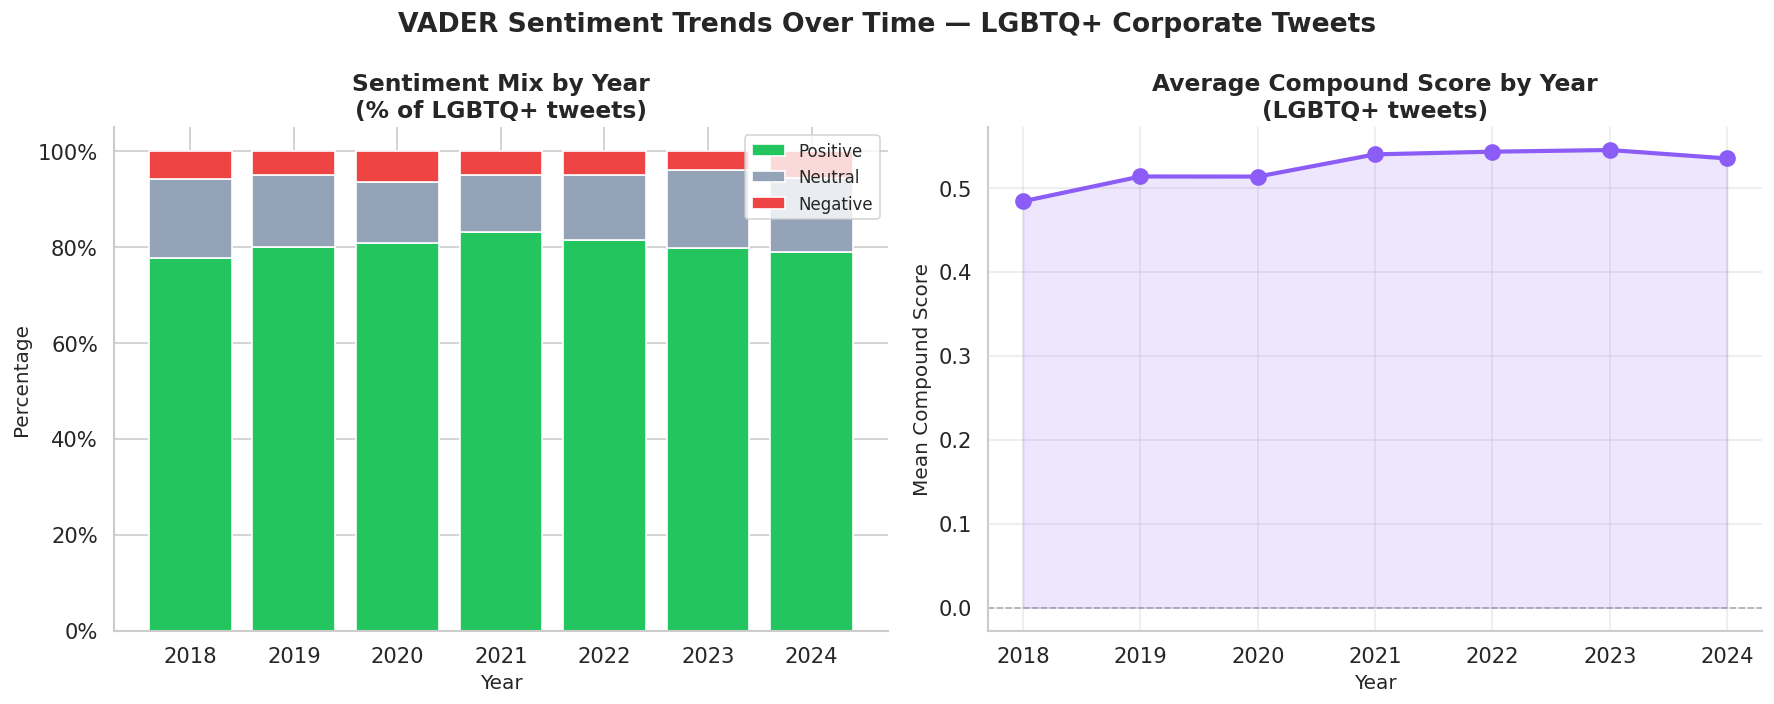

In [10]:
# ── Sentiment label counts by year ───────────────────────────────────────────
sent_by_year = (
    df_lgbtq.groupby(['year', 'vader_label'])
    .size()
    .reset_index(name='count')
)

# Pivot for stacked bar
sent_pivot = sent_by_year.pivot(index='year', columns='vader_label', values='count').fillna(0)
sent_pivot_pct = sent_pivot.div(sent_pivot.sum(axis=1), axis=0) * 100

# ── Stacked bar chart (%) ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

color_map = {'Positive': POS_COLOR, 'Neutral': NEU_COLOR, 'Negative': NEG_COLOR}

# Percentage stacked bar
bottom = np.zeros(len(sent_pivot_pct))
for label in ['Positive', 'Neutral', 'Negative']:
    if label in sent_pivot_pct.columns:
        vals = sent_pivot_pct[label].values
        axes[0].bar(sent_pivot_pct.index, vals, bottom=bottom,
                    label=label, color=color_map[label], edgecolor='white')
        bottom += vals

axes[0].set_title('Sentiment Mix by Year\n(% of LGBTQ+ tweets)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Percentage')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
axes[0].legend(loc='upper right', fontsize=10)
axes[0].set_xticks(sent_pivot_pct.index)
sns.despine(ax=axes[0])

# Mean compound score by year
compound_by_year = df_lgbtq.groupby('year')['vader_compound'].mean().reset_index()
axes[1].plot(
    compound_by_year['year'], compound_by_year['vader_compound'],
    marker='o', linewidth=2.5, color=LGBTQ_COLOR, markersize=9
)
axes[1].fill_between(compound_by_year['year'], compound_by_year['vader_compound'],
                      alpha=0.15, color=LGBTQ_COLOR)
axes[1].axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.6)
axes[1].set_title('Average Compound Score by Year\n(LGBTQ+ tweets)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Mean Compound Score')
axes[1].set_xticks(compound_by_year['year'])
axes[1].grid(True, alpha=0.4)
sns.despine(ax=axes[1])

fig.suptitle('VADER Sentiment Trends Over Time — LGBTQ+ Corporate Tweets')
plt.tight_layout()
plt.savefig('fig_vader_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2 — Sentiment by Month (Seasonality)

Does tone change across the calendar year, particularly during Pride Month in June?

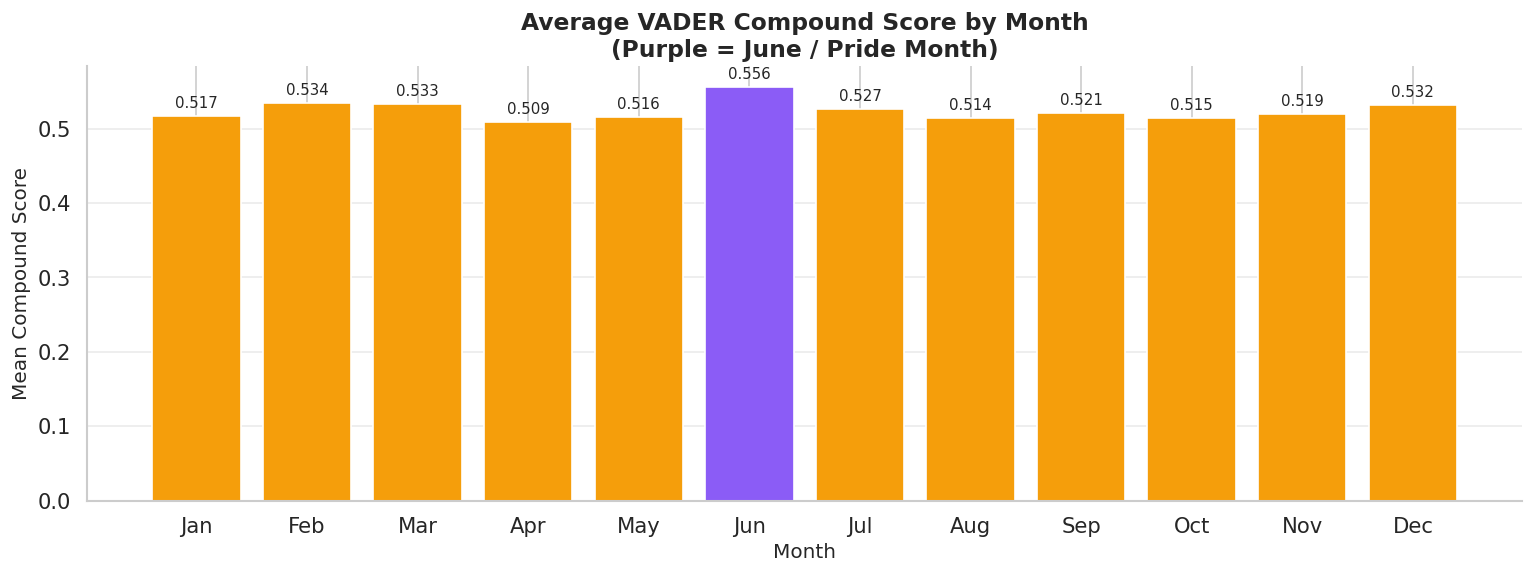

In [11]:
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

compound_by_month = (
    df_lgbtq.groupby('month')['vader_compound']
    .mean()
    .reset_index()
)
compound_by_month['month_name'] = compound_by_month['month'].apply(lambda m: month_names[m-1])

# Highlight June
bar_colors = [LGBTQ_COLOR if m == 6 else ACCENT_COLOR
              for m in compound_by_month['month']]

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(
    compound_by_month['month_name'],
    compound_by_month['vader_compound'],
    color=bar_colors, edgecolor='white'
)
ax.bar_label(bars, fmt='{:.3f}', padding=3, fontsize=9)
ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax.set_title('Average VADER Compound Score by Month\n(Purple = June / Pride Month)')
ax.set_xlabel('Month')
ax.set_ylabel('Mean Compound Score')
ax.grid(axis='y', alpha=0.4)
sns.despine()
plt.tight_layout()
plt.savefig('fig_vader_monthly.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 5 — Sentiment by Company

### 5.1 — Most Positive and Most Negative Companies

Which companies use the most celebratory language on LGBTQ+ topics — and which are more measured or negative? We require a minimum of 10 LGBTQ+ tweets per company to filter out noise from very small samples.

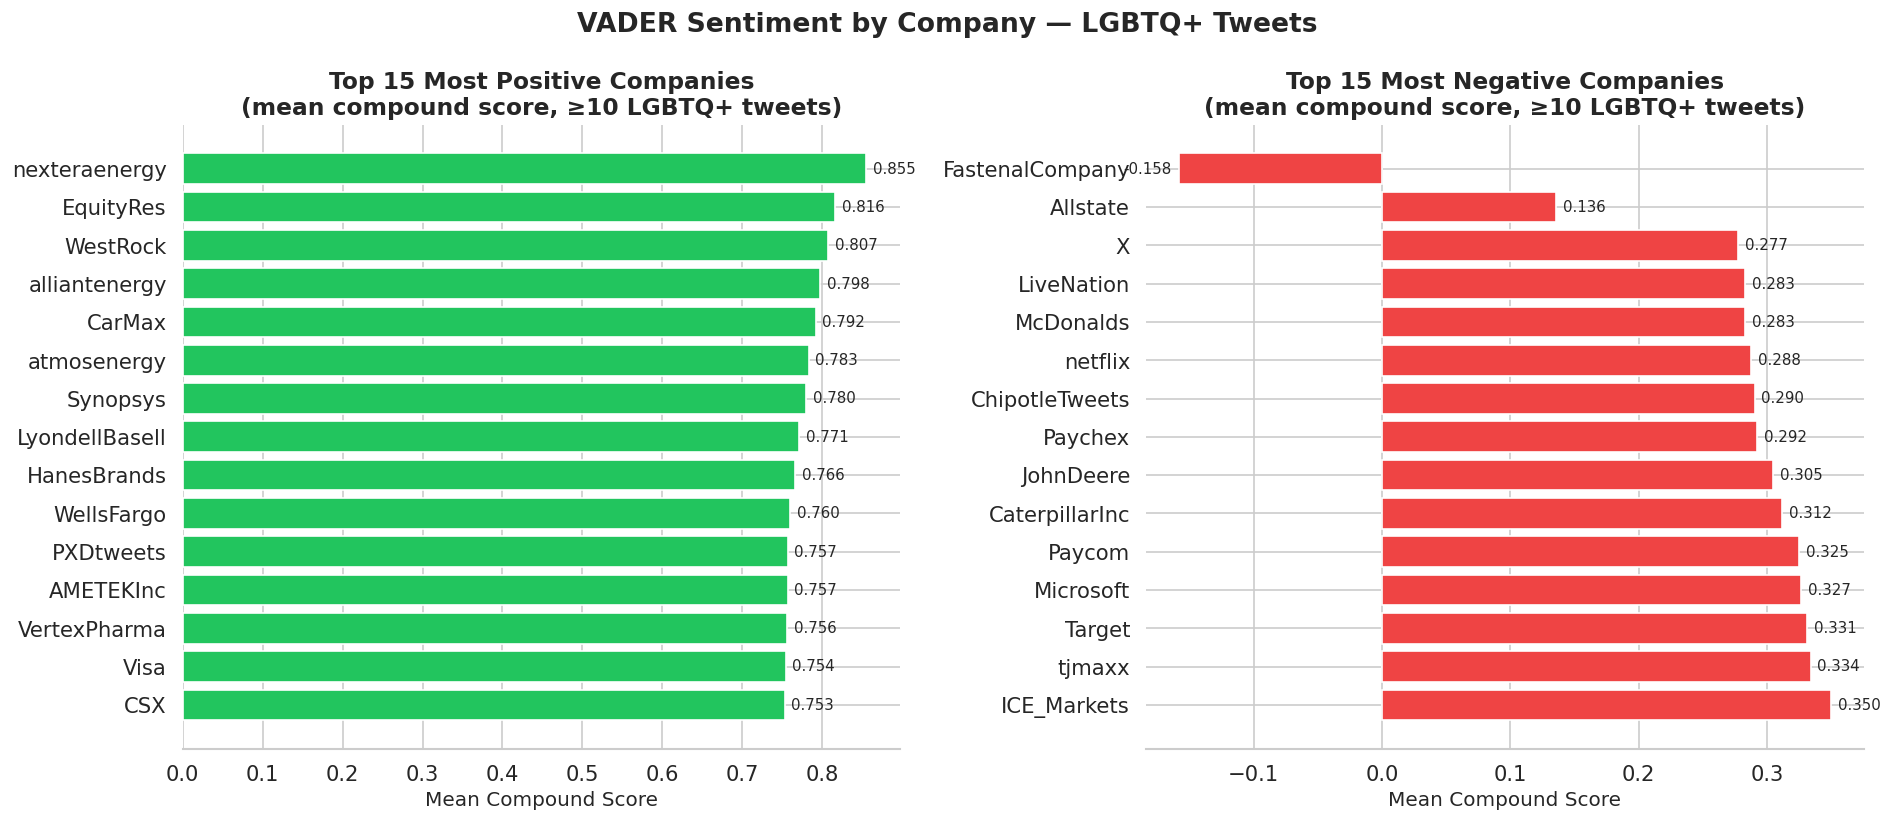

In [12]:
# ── Average compound score per company ───────────────────────────────────────
company_sent = (
    df_lgbtq.groupby('author_userName')
    .agg(
        mean_compound  = ('vader_compound', 'mean'),
        lgbtq_tweets   = ('vader_compound', 'count'),
        pct_positive   = ('vader_label', lambda x: (x == 'Positive').mean() * 100),
        pct_negative   = ('vader_label', lambda x: (x == 'Negative').mean() * 100),
    )
    .reset_index()
    .query('lgbtq_tweets >= 10')   # minimum 10 LGBTQ+ tweets for reliability
    .sort_values('mean_compound', ascending=False)
)

top15_pos = company_sent.head(15)
top15_neg = company_sent.tail(15).sort_values('mean_compound')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── Most positive ─────────────────────────────────────────────────────────────
bars = axes[0].barh(
    top15_pos['author_userName'][::-1],
    top15_pos['mean_compound'][::-1],
    color=POS_COLOR, edgecolor='white'
)
axes[0].bar_label(bars, fmt='{:.3f}', padding=4, fontsize=9)
axes[0].set_title('Top 15 Most Positive Companies\n(mean compound score, ≥10 LGBTQ+ tweets)')
axes[0].set_xlabel('Mean Compound Score')
sns.despine(ax=axes[0], left=True)

# ── Most negative ─────────────────────────────────────────────────────────────
bars = axes[1].barh(
    top15_neg['author_userName'][::-1],
    top15_neg['mean_compound'][::-1],
    color=NEG_COLOR, edgecolor='white'
)
axes[1].bar_label(bars, fmt='{:.3f}', padding=4, fontsize=9)
axes[1].set_title('Top 15 Most Negative Companies\n(mean compound score, ≥10 LGBTQ+ tweets)')
axes[1].set_xlabel('Mean Compound Score')
sns.despine(ax=axes[1], left=True)

fig.suptitle('VADER Sentiment by Company — LGBTQ+ Tweets')
plt.tight_layout()
plt.savefig('fig_vader_company_sentiment.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.2 — Full Company Sentiment Table

In [13]:
# ── Display ranked table of all qualifying companies ─────────────────────────
company_display = company_sent[['author_userName','lgbtq_tweets','mean_compound',
                                 'pct_positive','pct_negative']].copy()
company_display.columns = ['Company','LGBTQ+ Tweets','Mean Compound',
                            '% Positive','% Negative']
company_display = company_display.reset_index(drop=True)
company_display.index += 1

print(f'Companies with ≥10 LGBTQ+ tweets: {len(company_display)}')
display(
    company_display.style
    .format({
        'LGBTQ+ Tweets' : '{:,}',
        'Mean Compound' : '{:.3f}',
        '% Positive'    : '{:.1f}%',
        '% Negative'    : '{:.1f}%',
    })
    .background_gradient(subset=['Mean Compound'], cmap='RdYlGn')
)

Companies with ≥10 LGBTQ+ tweets: 354


,Company,LGBTQ+ Tweets,Mean Compound,% Positive,% Negative
1,nexteraenergy,17,0.855,100.0%,0.0%
2,EquityRes,30,0.816,100.0%,0.0%
3,WestRock,23,0.807,100.0%,0.0%
4,alliantenergy,12,0.798,91.7%,8.3%
5,CarMax,75,0.792,93.3%,1.3%
6,atmosenergy,37,0.783,94.6%,2.7%
7,Synopsys,21,0.780,100.0%,0.0%
8,LyondellBasell,102,0.771,97.1%,1.0%
9,HanesBrands,32,0.766,100.0%,0.0%
10,WellsFargo,157,0.760,96.8%,1.3%


---
## Section 6 — VADER vs. Pre-Existing Sentiment Scores

The dataset already contains a `sentiment` column. This section compares it to the VADER compound scores to see how well they agree.

Spearman correlation (VADER compound vs. existing sentiment):
   ρ = 0.162   p-value = 0.0000


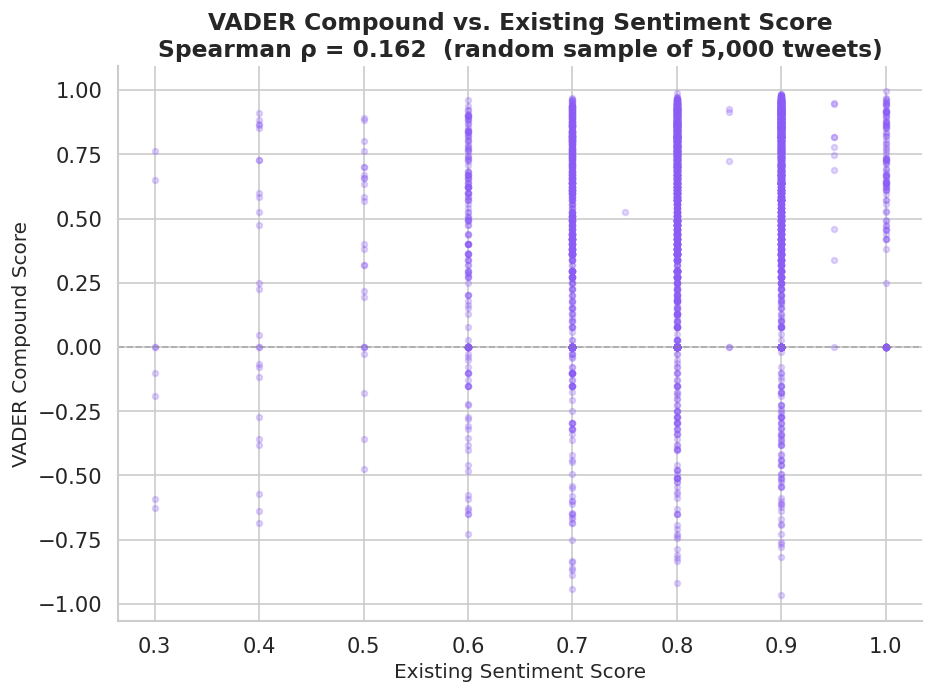

In [14]:
from scipy.stats import spearmanr

# ── Correlation between VADER compound and existing sentiment ────────────────
valid = df_lgbtq[['sentiment', 'vader_compound']].dropna()
rho, pval = spearmanr(valid['sentiment'], valid['vader_compound'])

print(f'Spearman correlation (VADER compound vs. existing sentiment):')
print(f'   ρ = {rho:.3f}   p-value = {pval:.4f}')

# ── Scatter plot ─────────────────────────────────────────────────────────────
sample = valid.sample(min(5000, len(valid)), random_state=42)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    sample['sentiment'],
    sample['vader_compound'],
    alpha=0.25, s=12, color=LGBTQ_COLOR
)
ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax.set_title(f'VADER Compound vs. Existing Sentiment Score\n'
             f'Spearman ρ = {rho:.3f}  (random sample of {len(sample):,} tweets)')
ax.set_xlabel('Existing Sentiment Score')
ax.set_ylabel('VADER Compound Score')
sns.despine()
plt.tight_layout()
plt.savefig('fig_vader_vs_existing.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 7 — Example Tweets by Sentiment Category

Reviewing real tweets from each category helps confirm the scores make intuitive sense — and gives you concrete examples to include in your paper.

In [15]:
# ── Pull top examples from each sentiment category ───────────────────────────
def get_examples(label, n=5):
    subset = df_lgbtq[df_lgbtq['vader_label'] == label].copy()
    if label == 'Positive':
        subset = subset.nlargest(n, 'vader_compound')
    elif label == 'Negative':
        subset = subset.nsmallest(n, 'vader_compound')
    else:
        subset = subset.iloc[:n]   # neutral: just take first few
    return subset[['author_userName', 'text', 'vader_compound']].reset_index(drop=True)

for label, color in [('Positive', POS_COLOR), ('Neutral', NEU_COLOR), ('Negative', NEG_COLOR)]:
    print(f'\n{"═"*60}')
    print(f'  {label.upper()} EXAMPLES')
    print(f'{"═"*60}')
    examples = get_examples(label)
    for _, row in examples.iterrows():
        print(f'  [{row["author_userName"]}]  compound={row["vader_compound"]:.3f}')
        print(f'  "{row["text"][:140]}"')
        print()

VADER measures the emotional valence of the language rather than the company's stance toward LGBTQ+ or diversity-related issues. Consequently, tweets discussing discrimination, violence, or hate crimes often receive strongly negative sentiment scores despite expressing solidarity and support. Conversely, celebratory Pride Month messages tend to receive highly positive scores, while informational or advocacy-oriented posts often score as neutral due to their relatively objective wording.

---
## Section 8 — Summary

### Key Findings

Use this table to record your headline results after running the notebook.

In [16]:
# ── Auto-generate key findings summary ───────────────────────────────────────
pct_pos = label_pcts.get('Positive', 0)
pct_neu = label_pcts.get('Neutral', 0)
pct_neg = label_pcts.get('Negative', 0)
mean_comp = df_lgbtq['vader_compound'].mean()
most_pos_co = company_sent.iloc[0]['author_userName'] if len(company_sent) > 0 else 'N/A'
most_neg_co = company_sent.iloc[-1]['author_userName'] if len(company_sent) > 0 else 'N/A'
best_month_idx = compound_by_month['vader_compound'].idxmax()
best_month = compound_by_month.loc[best_month_idx, 'month_name']

findings = pd.DataFrame([
    {'Metric': 'Total LGBTQ+ tweets analyzed',
     'Result': f'{len(df_lgbtq):,}'},
    {'Metric': 'Positive sentiment share',
     'Result': f'{pct_pos:.1f}%'},
    {'Metric': 'Neutral sentiment share',
     'Result': f'{pct_neu:.1f}%'},
    {'Metric': 'Negative sentiment share',
     'Result': f'{pct_neg:.1f}%'},
    {'Metric': 'Mean compound score (all LGBTQ+ tweets)',
     'Result': f'{mean_comp:.3f}'},
    {'Metric': 'Most positive company (mean compound)',
     'Result': most_pos_co},
    {'Metric': 'Most negative company (mean compound)',
     'Result': most_neg_co},
    {'Metric': 'Month with highest average sentiment',
     'Result': best_month},
    {'Metric': 'Spearman ρ (VADER vs. existing sentiment)',
     'Result': f'{rho:.3f}'},
])

print('VADER SENTIMENT ANALYSIS — KEY FINDINGS SUMMARY')
display(findings.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

VADER SENTIMENT ANALYSIS — KEY FINDINGS SUMMARY


Metric,Result
Total LGBTQ+ tweets analyzed,"52,791"
Positive sentiment share,80.6%
Neutral sentiment share,14.3%
Negative sentiment share,5.1%
Mean compound score (all LGBTQ+ tweets),0.527
Most positive company (mean compound),nexteraenergy
Most negative company (mean compound),FastenalCompany
Month with highest average sentiment,Jun
Spearman ρ (VADER vs. existing sentiment),0.162


## Saved Figures

- `fig_vader_overall_dist.png` — Bar and pie chart of overall sentiment distribution
- `fig_vader_compound_dist.png` — Histogram of compound scores
- `fig_vader_yearly_trend.png` — Sentiment mix and mean compound score by year
- `fig_vader_monthly.png` — Average compound score by month
- `fig_vader_company_sentiment.png` — Most positive and most negative companies
- `fig_vader_vs_existing.png` — VADER vs. pre-existing sentiment scores

---
